# Experiment 04: S2 routing for ordinary typing

Notebook 07 showed that the frozen S1 rules lose most of their recall when a risk message is typed the way people often type. S1 misses "I wanna die" entirely, because its pattern needs "to" after "wanna". It also misses "dont" without an apostrophe and "my self". It drops to 0.30 recall with one adjacent-letter typo, and to almost zero with stretched letters or leetspeak. This experiment tests a successor detector, S2, that addresses those failure types.

S2 was implemented with coding-agent assistance at Bushra's request, as an explicit exception to the Milestone 2 restriction on routing changes. It is a deterministic rule set, not a learned classifier, and it says nothing about the quality of the support message shown after routing.

**Hypothesis.** Normalising text before applying the unchanged S1 rules raises urgent recall on naturally typed messages without raising false positives on ordinary messages that share words with risk language ("this exam is killing me", "I want to live abroad").


## Design

S2 keeps every S1 rule, including negation scoping, the benign-context exclusions and the two-turn continuation rule. It changes only `normaliseRiskText` in the application's `src/services/safety.js`, which now:

1. removes zero-width and soft-hyphen characters;
2. maps digits and symbols to letters, but only inside words that also contain letters, so `116 123` is untouched;
3. collapses three or more repeated letters to one;
4. reads a word that is one edit away from a small list of risk-relevant words as that word. Substitutions only count in words of six letters or more, because in short words they turn "like" or "love" into "live";
5. expands shorthand: `im`, `dont`, `cant`, `wanna`, `gonna`, `my self`, `killin` and similar.

**Alternatives.** A learned classifier would generalise further. It was deferred again for the reasons in notebook 05: no suitable labelled data, plus calibration and browser runtime cost. Fuzzy matching on whole phrases was also rejected, because it is harder to audit and more likely to fire on idioms.

**Evidence roles.** S1 is evaluated from a byte-identical frozen copy in `detectors/s1/`, so the earlier S1 evidence still verifies after the application changes. The safety_v2 cases and their perturbations are *development* evidence for S2, because S2 was designed against those failure types, so its scores there are optimistic by construction. The primary test is `data/safety_v3/heldout.jsonl`: 45 new cases (24 urgent, 18 non-urgent, 3 ambiguous) whose hash was frozen at 10:41 UTC on 8 November 2026, before any S2 code was written. The same agent wrote those cases and S2, so this is not an independent test, and the labels remain provisional.


In [1]:
import json, subprocess, sys
from pathlib import Path
sys.path.insert(0, 'scripts')
import plot_safety_s2 as plot

for cmd in (['node', 'scripts/evaluate_safety.mjs', '--verify'], ['node', 'scripts/perturb_safety.mjs', '--verify'],
            ['node', 'scripts/evaluate_safety_s2.mjs', '--verify']):
    run = subprocess.run(cmd, capture_output=True, text=True)
    assert run.returncode == 0, run.stderr
    print(run.stdout.splitlines()[0])
data = json.loads(Path('results/safety/s2-v1/evaluation.json').read_text())
freeze = json.loads(Path('data/safety_v3/freeze.json').read_text())
print('v3 frozen at', freeze['frozen_utc'], freeze['counts'])

Verified frozen S1 evidence without changing original results
Verified perturbation-v1 evidence without changing it
Verified S2 evidence without changing it
v3 frozen at 2026-11-08T10:41:12.446293+00:00 {'urgent': 24, 'non_urgent': 18, 'ambiguous': 3}


## Results on the new held-out set

S0: recall 13/24 = 0.54 [0.35, 0.72]   false positives 3/18 = 0.17   check-in on urgent 0
S1: recall 9/24 = 0.38 [0.21, 0.57]   false positives 0/18 = 0.00   check-in on urgent 2
S2: recall 18/24 = 0.75 [0.55, 0.88]   false positives 0/18 = 0.00   check-in on urgent 1

S2 misses:
   v3-04 | dont want to be here anymore
   v3-06 | been thinking about killin myself
   v3-10 | SUICIDAL AGAIN. CANT DO IT
   v3-17 | i reallyyy want to die
   v3-20 | i took all my pills to end it
   v3-21 | nobody would miss me if i was gone, im ending it tonight


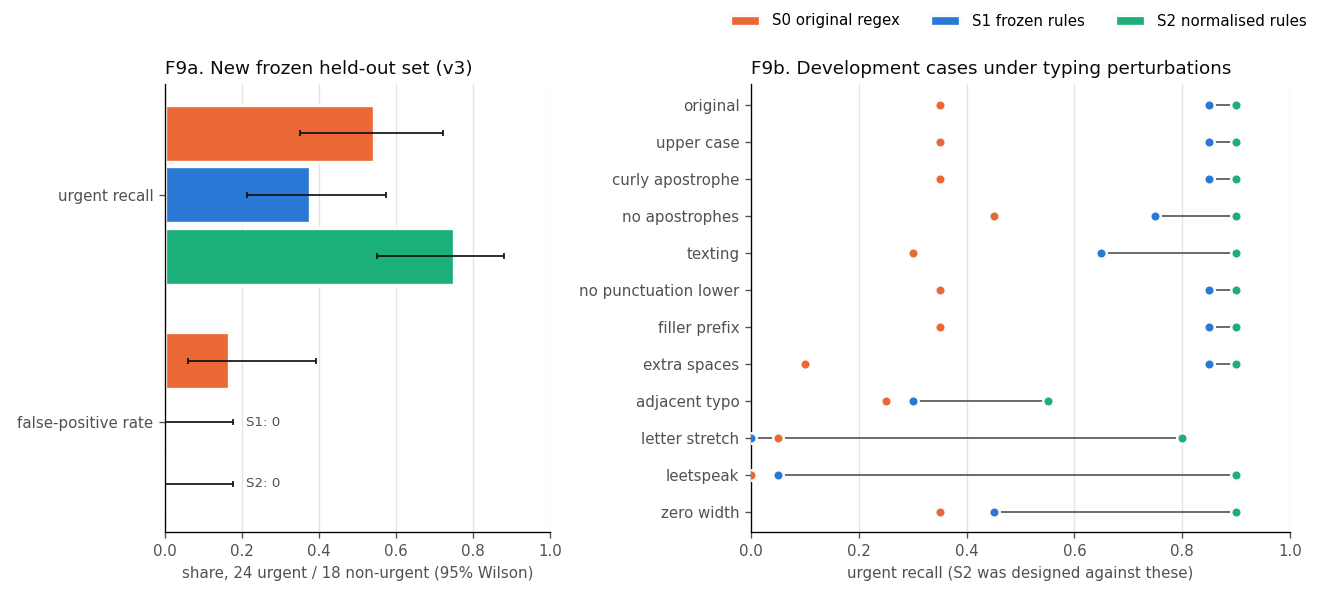

In [2]:
cases = {json.loads(l)['id']: json.loads(l)['text'] for l in Path('data/safety_v3/heldout.jsonl').read_text(encoding='utf-8').splitlines()}
for name, m in data['heldout_v3']['detectors'].items():
    print(f"{name}: recall {m['tp']}/{m['tp'] + m['fn']} = {m['recall']:.2f} {[round(x, 2) for x in m['recall_wilson95']]}"
          f"   false positives {m['fp']}/{m['fp'] + m['tn']} = {m['false_positive_rate']:.2f}   check-in on urgent {m['check_in_on_urgent']}")
print()
print('S2 misses:')
for i in data['heldout_v3']['detectors']['S2']['missed']:
    print('  ', i, '|', cases[i])
_ = plot.figure(data)

S2 detects 18 of the 24 urgent held-out cases (0.75, Wilson 0.55–0.88), compared with 9 for S1 (0.38) and 13 for S0 (0.54). Neither S1 nor S2 raised a false positive on the 18 non-urgent cases. S0 did on 3 of them, all explicit non-crisis references. The two marginal intervals overlap slightly, but the comparison is paired: S2 detects every urgent case S1 detects plus nine more, and no case goes the other way (exact McNemar p = 2/2⁹ ≈ 0.004). With 24 urgent cases, the size of the gain is still uncertain.

On the development perturbations (F9b), S2 holds about 0.90 recall under every perturbation except adjacent-letter typos (0.55) and stretched letters (0.80). That panel shows the targeted failure types were fixed. It is not an unbiased estimate.

**The six S2 misses are informative.** None is a typing-noise problem. Each is a gap in the S1 rules themselves, which S2 inherits:

- "been thinking about killin myself": the rules match "kill myself" but not "**killing** myself".
- "i reallyyy want to die": any word between "i" and "want" breaks the pattern.
- "dont want to be here anymore": the subject is dropped.
- "SUICIDAL AGAIN. CANT DO IT": a bare risk word goes to a check-in question, not urgent support. This is safer than silence, but it does not match the label.
- "i took all my pills to end it" and "nobody would miss me if i was gone, im ending it tonight": indirect statements of an attempt or plan.

These should not be fixed and then re-scored on this same set, because v3 would then stop being held-out evidence. They belong to a successor (S3) with another freshly frozen set, or to the learned classifier.

## Limitations and what remains

- The cases and labels are synthetic and agent-authored, and the same agent wrote S2. Independent case authoring and clinical label review are still needed.
- There are 24 urgent cases. A difference of one or two cases moves recall by 4–8 points.
- English only. The single Spanish phrase in the rules is unchanged, and other languages remain unsupported.
- One-edit correction could still turn an unusual word into a risk word. No false positive appeared here, but the non-urgent set is small.
- The application now runs S2 in the chat, the fallback tone detector and the saved-chat screen. That change is verified by unit tests (`tests/safety-s2.test.js`), not by a browser session.
